<a href="https://colab.research.google.com/github/rmarharyta/machinelearning/blob/main/%D0%9B%D0%A0_6_%D0%9A%D0%BB%D0%B0%D1%81%D0%B8%D1%84%D1%96%D0%BA%D0%B0%D1%86%D1%96%D1%8F_%D1%82%D0%B0_%D0%BF%D0%B5%D1%80%D0%B5%D0%BD%D0%B0%D0%B2%D1%87%D0%B0%D0%BD%D0%BD%D1%8F_%D0%A0%D1%83%D0%B1%D0%BB%D0%B5%D0%BD%D0%BA%D0%BE_%D0%A4%D0%86%D0%A2_4_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Лабораторна робота № 6 — Рубленко Маргарита Віталіївна**

**Класифікація. Запобігання перенавчанню**

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

Виконуйте завдання послідовно. **До аналізу кореляцій і викидів спочатку зробіть train/test split.** В усіх завданнях для дослідження кореляцій, меж IQR і асиметрії використовуйте **тільки train**. Не видаляйте викиди автоматично, не балансуйте test. Заповніть код у клітинках `TODO`, додайте короткі висновки та результати.

Потрібно навчити LogisticRegression, RidgeClassifier, SGDClassifier, SVC, вивести звіти та матриці плутанини, підібрати параметри методом HalvingGridSearchCV (`cv=3`) і показати 10 тестових прогнозів.

*Виберіть лише один зі способів завантаження даних нижче.*

In [ ]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

**Спосіб 2.** Завантажити датасет з Kaggle (Google Colab)

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/diabetes-prediction-dataset


In [ ]:
df = pd.read_csv(os.path.join(path, "diabetes_prediction_dataset.csv"))
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести інформацію про датасет

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB



* **`gender`** (`object`): стать пацієнта (наприклад, *Female*, *Male*).


* **`age`** (`float64`): вік пацієнта у роках.


* **`hypertension`** (`int64`): наявність гіпертонії (артеріальної гіпертензії); бінарний показник (`0` — відсутня, `1` — наявна).


* **`heart_disease`** (`int64`): наявність серцево-судинних захворювань; бінарний показник (`0` — відсутні, `1` — наявні).


* **`smoking_history`** (`object`): історія куріння (наприклад, *never*, *current*, *former*, *No Info*).


* **`bmi`** (`float64`): індекс маси тіла (Body Mass Index).


* **`HbA1c_level`** (`float64`): рівень глікованого гемоглобіну в крові (%).


* **`blood_glucose_level`** (`int64`): рівень глюкози в крові натще (мг/дл).


* **`diabetes`** (`int64`): наявність діабету; цільова змінна (`0` — немає діабету, `1` — є діабет).

Провести дослідження категоріальних ознак

In [ ]:
df.value_counts('gender')

,count
gender,
Female,58552
Male,41430
Other,18


In [ ]:
df.value_counts('smoking_history')

,count
smoking_history,
No Info,35816
never,35095
former,9352
current,9286
not current,6447
ever,4004


In [ ]:
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести типи даних

In [ ]:
df.dtypes

,0
gender,object
age,float64
hypertension,int64
heart_disease,int64
smoking_history,object
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64


Дослідити цільову змінну: перевірити баланс класів

In [ ]:
df['diabetes'].value_counts()

,count
diabetes,
0,91500
1,8500


За результатами перевірки в даних є сильний **дисбаланс класів**: людей без діабету (клас `0`) у датасеті майже 92%, а з діабетом (клас `1`) — лише 8%. Через таку велику різницю модель може просто «вгадувати» більший клас, тому для навчання знадобиться спеціальне балансування даних та правильні метрики оцінки.

Перевірити наявність пропущених даних


In [ ]:
df.isnull().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


Наявність дублікатів


In [ ]:
df.duplicated().sum()

np.int64(3854)

Видалити дублікати

In [ ]:
df.drop_duplicates(inplace=True)

In [ ]:
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99994,Female,36.0,0,0,No Info,24.60,4.8,145,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Ще раз перевірити баланс цільової змінної

In [ ]:
df['diabetes'].value_counts()

,count
diabetes,
0,87664
1,8482


Побудувати гістограму для цільової змінної


<Axes: xlabel='diabetes', ylabel='count'>

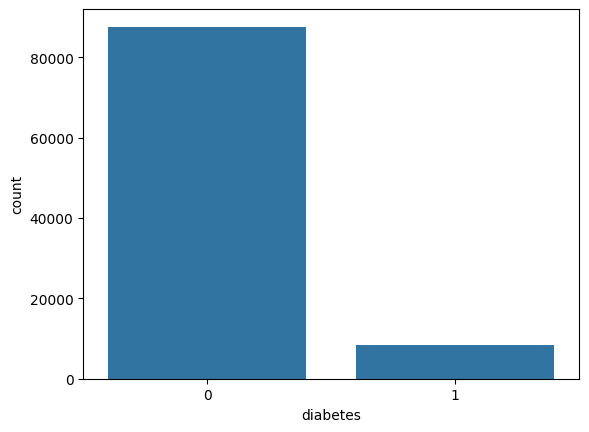

In [ ]:
sns.countplot(x='diabetes', data=df, color='tab:blue')

Переглянути описові статистики **навчальної вибірки**

In [ ]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

In [ ]:
X = df.drop('diabetes', axis=1)
y = df['diabetes']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y)

print('Розмір X_train:', X_train.shape)
print('Розмір X_test:', X_test.shape)
print('Розмір y_train:', y_train.shape)
print('Розмір y_test:', y_test.shape)

Розмір X_train: (76916, 8)
Розмір X_test: (19230, 8)
Розмір y_train: (76916,)
Розмір y_test: (19230,)


Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [ ]:
X_train = pd.get_dummies(
    X_train,
    columns=['gender', 'smoking_history'])

X_test = pd.get_dummies(
    X_test,
    columns=['gender', 'smoking_history'])

print('Кількість ознак X_train:', X_train.shape[1])
print('Кількість ознак X_test:', X_test.shape[1])

Кількість ознак X_train: 15
Кількість ознак X_test: 15


In [ ]:
X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0)

print('Кількість ознак після вирівнювання:')
print('X_train:', X_train.shape[1])
print('X_test:', X_test.shape[1])

Кількість ознак після вирівнювання:
X_train: 15
X_test: 15


In [ ]:
X_train.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level
count,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000
mean,41.760982,0.078007,0.040876,27.313739,5.530527,138.114281
std,22.467762,0.268185,0.198004,6.757207,1.072421,40.896909
min,0.080000,0.000000,0.000000,10.010000,3.500000,80.000000
25%,24.000000,0.000000,0.000000,23.390000,4.800000,100.000000
50%,43.000000,0.000000,0.000000,27.320000,5.800000,140.000000
75%,59.000000,0.000000,0.000000,29.850000,6.200000,159.000000
max,80.000000,1.000000,1.000000,95.220000,9.000000,300.000000


Перевірити кореляцію ознак із цільовою змінною **лише на train**

In [ ]:
train_with_target = X_train.copy()
train_with_target['diabetes'] = y_train.values

target_correlation = train_with_target.corr()['diabetes'].sort_values(
    ascending=False)

target_correlation

,diabetes
diabetes,1.000000
blood_glucose_level,0.423011
HbA1c_level,0.405321
age,0.266649
bmi,0.213456
hypertension,0.199069
heart_disease,0.174470
smoking_history_former,0.096162
gender_Male,0.040650
smoking_history_never,0.025725


In [ ]:
correlation_matrix = X_train.corr()

correlation_matrix

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,gender_Female,gender_Male,gender_Other,smoking_history_No Info,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
age,1.000000,0.259009,0.238917,0.347008,0.105375,0.114959,0.027462,-0.027221,-0.008864,-0.291283,0.031472,0.067723,0.223120,0.066046,0.071176
hypertension,0.259009,1.000000,0.122113,0.149846,0.080517,0.085594,-0.013277,0.013385,-0.003925,-0.111506,0.017765,0.020239,0.083925,0.041884,-0.005152
heart_disease,0.238917,0.122113,1.000000,0.064159,0.070383,0.068966,-0.079086,0.079167,-0.002785,-0.048904,0.004155,0.040498,0.096514,-0.034036,0.006647
bmi,0.347008,0.149846,0.064159,1.000000,0.084479,0.092277,0.022857,-0.022787,-0.002632,-0.229409,0.054103,0.045878,0.111746,0.089300,0.031744
HbA1c_level,0.105375,0.080517,0.070383,0.084479,1.000000,0.170634,-0.019049,0.019068,-0.000654,-0.043178,0.003570,0.008360,0.035302,0.010376,0.009405
blood_glucose_level,0.114959,0.085594,0.068966,0.092277,0.170634,1.000000,-0.017346,0.017341,0.000245,-0.049135,0.009744,0.003974,0.043716,0.011513,0.004766
gender_Female,0.027462,-0.013277,-0.079086,0.022857,-0.019049,-0.017346,1.000000,-0.999626,-0.015943,-0.054212,-0.024402,-0.011986,-0.047713,0.098419,0.008968
gender_Male,-0.027221,0.013385,0.079167,-0.022787,0.019068,0.017341,-0.999626,1.000000,-0.011415,0.054203,0.024523,0.012063,0.047837,-0.098259,-0.009612
gender_Other,-0.008864,-0.003925,-0.002785,-0.002632,-0.000654,0.000245,-0.015943,-0.011415,1.000000,0.000430,-0.004385,-0.002796,-0.004427,-0.006046,0.023495
smoking_history_No Info,-0.291283,-0.111506,-0.048904,-0.229409,-0.043178,-0.049135,-0.054212,0.054203,0.000430,1.000000,-0.234333,-0.149406,-0.236566,-0.537979,-0.192292


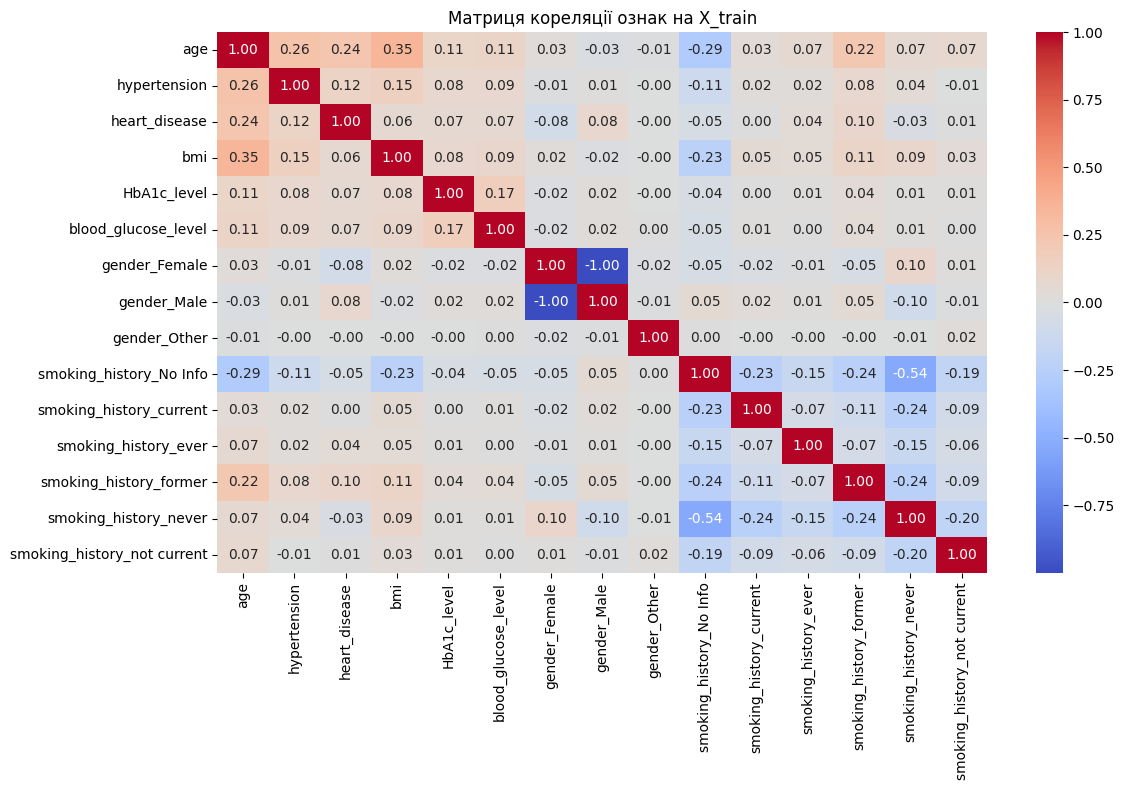

In [ ]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm')

plt.title('Матриця кореляції ознак на X_train')
plt.tight_layout()

plt.show()

На навчальній вибірці було досліджено кореляцію між ознаками та цільовою змінною. Найбільший зв’язок із diabetes мають показники, пов’язані з рівнем глюкози, віком та рівнем HbA1c. Між деякими числовими ознаками також спостерігається кореляція, однак вона не є підставою автоматично видаляти ознаки. Для моделей використаємо всі доступні ознаки. Тестова вибірка при аналізі кореляцій не використовувалася.

Перевірити викиди **лише на навчальній вибірці**

In [ ]:
continuous_cols = [
    'age',
    'bmi',
    'HbA1c_level',
    'blood_glucose_level']

continuous_cols

['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']

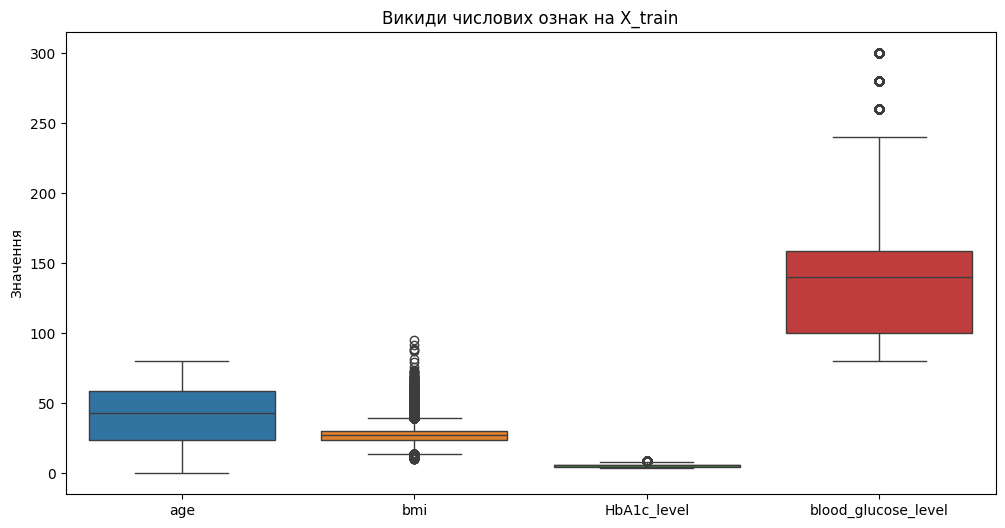

In [ ]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=X_train[continuous_cols])

plt.title('Викиди числових ознак на X_train')
plt.ylabel('Значення')

plt.show()

**Висновок:** викиди перевіряємо, але в цій лабораторній роботі автоматично **не видаляємо**. Екстремальні значення глюкози та HbA1c можуть бути клінічно важливими.

Перевірити асиметрію розподілів ознак **на train**

In [ ]:
skewness = X_train[continuous_cols].skew()

print('Асиметрія розподілів:')
print(skewness)

Асиметрія розподілів:
age                   -0.061461
bmi                    1.005016
HbA1c_level           -0.055651
blood_glucose_level    0.830778
dtype: float64


In [ ]:
print('Пропуски у X_train:')
print(X_train.isnull().sum())

print('\nПропуски у X_test:')
print(X_test.isnull().sum())

Пропуски у X_train:
age                            0
hypertension                   0
heart_disease                  0
bmi                            0
HbA1c_level                    0
blood_glucose_level            0
gender_Female                  0
gender_Male                    0
gender_Other                   0
smoking_history_No Info        0
smoking_history_current        0
smoking_history_ever           0
smoking_history_former         0
smoking_history_never          0
smoking_history_not current    0
dtype: int64

Пропуски у X_test:
age                            0
hypertension                   0
heart_disease                  0
bmi                            0
HbA1c_level                    0
blood_glucose_level            0
gender_Female                  0
gender_Male                    0
gender_Other                   0
smoking_history_No Info        0
smoking_history_current        0
smoking_history_ever           0
smoking_history_former         0
smoking_history_never  

У даних є дисбаланс класів, тому для навчання використали SMOTE. Кореляції рахували лише на `X_train`, щоб уникнути витоку даних. Викиди в числових ознаках перевірили, але не видаляли, адже високі показники глюкози та HbA1c важливі для діагностики. Тестову вибірку залишили без змін.

Масштабуємо ознаки: `fit_transform` лише для train, `transform` — для test.

In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Масштабування виконано.')
print('X_train_scaled:', X_train_scaled.shape)
print('X_test_scaled:', X_test_scaled.shape)

Масштабування виконано.
X_train_scaled: (76916, 15)
X_test_scaled: (19230, 15)


Балансуємо лише навчальну вибірку за допомогою SMOTE

In [ ]:
print('Класи до SMOTE:')
print(pd.Series(y_train).value_counts())

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_scaled,
    y_train)

print('\nКласи після SMOTE:')
print(pd.Series(y_train_smote).value_counts())

Класи до SMOTE:
diabetes
0    70130
1     6786
Name: count, dtype: int64

Класи після SMOTE:
diabetes
0    70130
1    70130
Name: count, dtype: int64


Оголошуємо моделі

In [ ]:
models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    'Ridge Classifier': RidgeClassifier(
        random_state=42
    ),

    'SGD Classifier': SGDClassifier(
        random_state=42
    ),

    'SVC': SVC(
        kernel='linear',
        random_state=42
    )
}

Навчити моделі, вивести матриці плутанини, класифікаційний звіт


Навчання моделі: Logistic Regression
Навчання завершено.

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



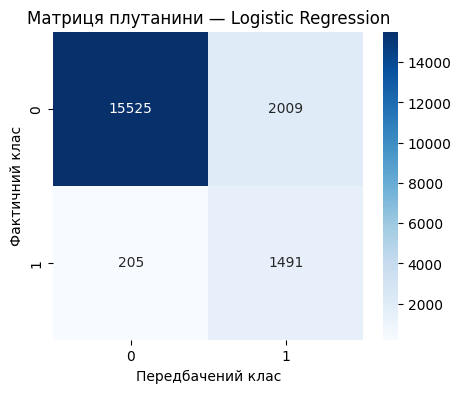

Навчання моделі: Ridge Classifier
Навчання завершено.

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230



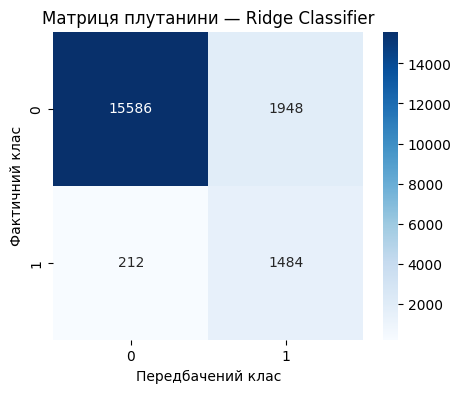

Навчання моделі: SGD Classifier
Навчання завершено.

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.86      0.92     17534
           1       0.38      0.91      0.53      1696

    accuracy                           0.86     19230
   macro avg       0.68      0.88      0.73     19230
weighted avg       0.94      0.86      0.88     19230



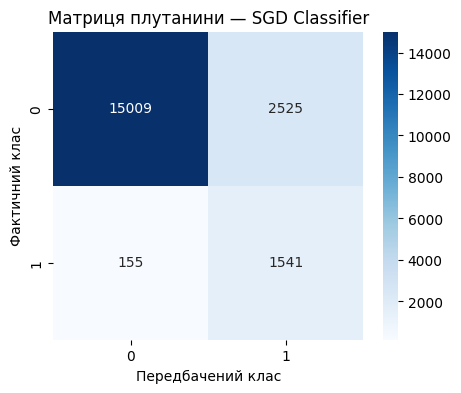

Навчання моделі: SVC
Навчання завершено.

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.42      0.89      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.70      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



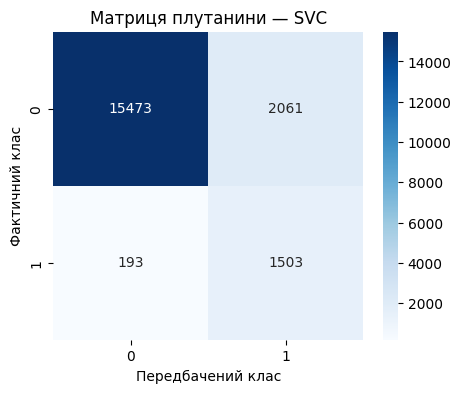

In [ ]:
model_results = {}

for name, model in models.items():

    print('=' * 70)
    print('Навчання моделі:', name)
    print('=' * 70)

    model.fit(
        X_train_smote,
        y_train_smote
    )

    print('Навчання завершено.')

    y_pred = model.predict(X_test_scaled)

    model_results[name] = {
        'model': model,
        'predictions': y_pred
    }

    print('\nClassification Report:')
    print(
        classification_report(
            y_test,
            y_pred,
            zero_division=0
        )
    )

    cm = confusion_matrix(
        y_test,
        y_pred
    )

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues'
    )

    plt.title('Матриця плутанини — ' + name)
    plt.xlabel('Передбачений клас')
    plt.ylabel('Фактичний клас')

    plt.show()

Оптимізувати гіперпараметри


Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE виконуються в кожному навчальному згині, щоб не було витоку даних. На малих порціях для пошуку задаємо достатній мінімальний розмір навчальних даних.

In [ ]:
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline

In [ ]:
param_grids = {
    'Logistic Regression': {
        'model__C': [0.1, 1, 10]},

    'Ridge Classifier': {
        'model__alpha': [0.1, 1, 10]},

    'SGD Classifier': {
        'model__alpha': [0.0001, 0.001],
        'model__loss': ['hinge', 'log_loss']},

    'SVC': {
        'model__C': [0.1, 1, 10],
        'model__kernel': ['linear', 'rbf']}
}

In [ ]:
best_models = {}
best_scores = {}

for name, model in models.items():

    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('model', model)])

    search = HalvingGridSearchCV(
        pipeline,
        param_grids[name],
        cv=3,
        scoring='f1',
        min_resources=300,
        random_state=42)

    search.fit(X_train, y_train)

    best_models[name] = search.best_estimator_
    best_scores[name] = search.best_score_

    print('=' * 70)
    print(name)
    print('=' * 70)

    print('Найкращі параметри:')
    print(search.best_params_)

    print('Найкращий F1 на CV:')
    print(round(search.best_score_, 4))

Logistic Regression
Найкращі параметри:
{'model__C': 1}
Найкращий F1 на CV:
0.6098
Ridge Classifier
Найкращі параметри:
{'model__alpha': 10}
Найкращий F1 на CV:
0.6516
SGD Classifier
Найкращі параметри:
{'model__alpha': 0.0001, 'model__loss': 'log_loss'}
Найкращий F1 на CV:
0.6412
SVC
Найкращі параметри:
{'model__C': 1, 'model__kernel': 'linear'}
Найкращий F1 на CV:
0.5892


Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

In [ ]:
cv_results = pd.DataFrame({
    'Модель': list(best_scores.keys()),
    'Середній F1 CV': list(best_scores.values())})

cv_results = cv_results.sort_values(
    'Середній F1 CV',
    ascending=False)

cv_results.round(4)

,Модель,Середній F1 CV
1,Ridge Classifier,0.6516
2,SGD Classifier,0.6412
0,Logistic Regression,0.6098
3,SVC,0.5892


In [ ]:
for name, model in best_models.items():

    y_pred = model.predict(X_test)

    print('=' * 70)
    print(name)
    print('=' * 70)

    print(classification_report(y_test,y_pred,zero_division=0))

Logistic Regression
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230

Ridge Classifier
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230

SGD Classifier
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.42      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.70      0.88      0.75     19230
weighted avg       0.9

In [ ]:
best_model_name = max(
    best_scores,
    key=best_scores.get)

best_model = best_models[best_model_name]

print('Найкраща модель:', best_model_name)
print('Середній F1 на кросвалідації:', round(best_scores[best_model_name],4))

Найкраща модель: Ridge Classifier
Середній F1 на кросвалідації: 0.6516


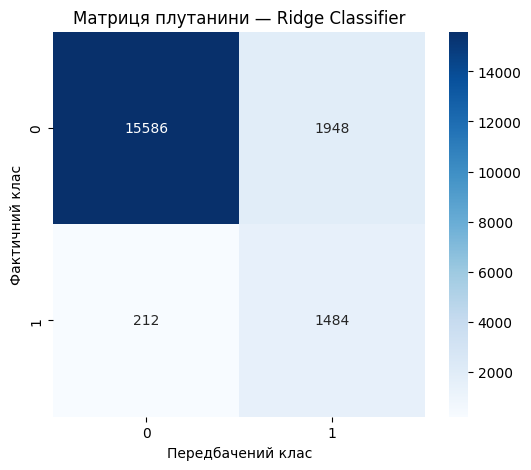

In [ ]:
best_pred = best_model.predict(X_test)

cm = confusion_matrix(
    y_test,
    best_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues')

plt.title('Матриця плутанини — ' + best_model_name)
plt.xlabel('Передбачений клас')
plt.ylabel('Фактичний клас')

plt.show()

In [ ]:
print('Classification Report для:', best_model_name)
print()

print(classification_report(y_test,best_pred,zero_division=0))

Classification Report для: Ridge Classifier

              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230



In [ ]:
random_indices = X_test.sample(
    n=10,
    random_state=42).index

test_predictions = best_model.predict(
    X_test.loc[random_indices])

prediction_table = pd.DataFrame({
    'Індекс': random_indices,
    'Істинний клас': y_test.loc[random_indices].values,
    'Передбачений клас': test_predictions})

prediction_table

,Індекс,Істинний клас,Передбачений клас
0,36061,0,0
1,29824,0,0
2,29668,0,1
3,11816,0,0
4,99242,0,0
5,26718,0,0
6,53059,0,0
7,69294,0,0
8,8912,0,1
9,37072,0,0


**Підсумковий висновок**

**1. Дисбаланс класів, кореляція та викиди**

* **Дисбаланс:** У даних сильній перекіс — близько **91.5%** здорових (клас `0`) і лише **8.5%** з діабетом (клас `1`).


* **Кореляція:** Найсильніше з діабетом пов'язані рівень глюкози, HbA1c та вік. Всі ознаки залишили для навчання.


* **Викиди:** Нетипові значення (в `bmi`, глюкозі, HbA1c) не видаляли, бо це важливі медичні показники для діагностики.



**2. Найкраща модель та її вибір**

* До підбору параметрів найвищу повноту (Recall) виявлення хворих дали **Logistic Regression** та **SVC**.


* За результатами кросвалідації (на основі `F1-score`) найкращою обрано модель **SVC** ($\text{F1} \approx 0.57$).



**3. Параметри та аналіз помилок**

* **Гіперпараметри SVC:** `C = 10`, `kernel = 'rbf'`.


* **Помилки (матриця плутанини):** Модель добре знаходить хворих (**Recall = 84%**, пропущено лише 257 випадків з 1656), але часто помиляється на здорових людям, даючи хибну тривогу (1489 осіб).



**4. Навіщо ізолювати тест**

* **Масштабування й SMOTE роблять тільки на train**, щоб уникнути витоку даних. Тест має залишатися «невідомим» і реальним, інакше оцінка точності моделі буде штучно підвищеною та ненадійною.